Original Dataset:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500  

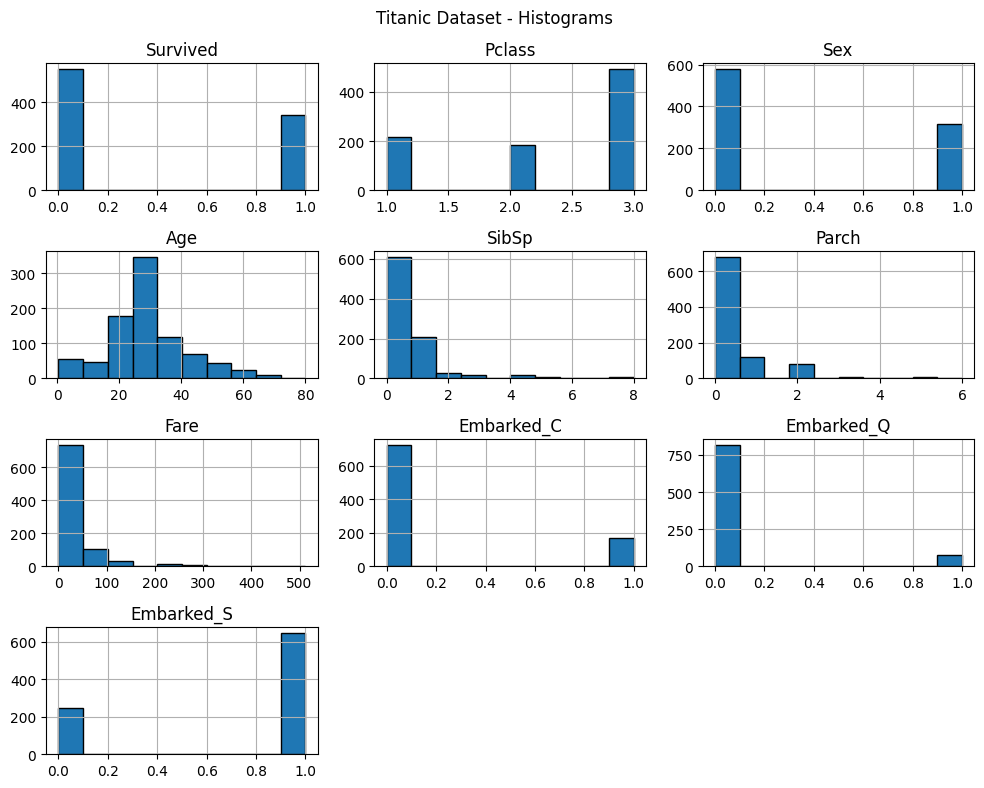

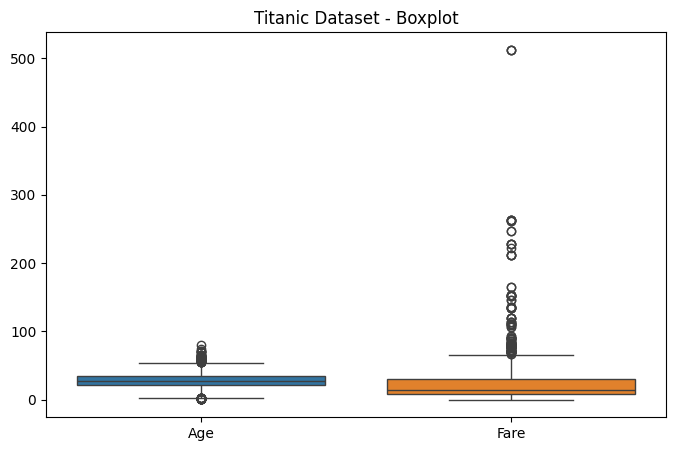

Final Training Data Shape: (712, 9)
Final Testing Data Shape: (179, 9)

Practical 5 Completed Successfully!


In [2]:

# PR5: Data Preprocessing and Exploratory Data Analysis

# * TASK 1: Import libraries and load dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Titanic-Dataset.csv")

print("Original Dataset:")
print(df.head())


# * TASK 2: Display dataset information
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe(include="all"))


# * TASK 3: Check missing values
print("Missing Values:")
print(df.isnull().sum())


# * TASK 4: Handle missing values
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Fare"] = df["Fare"].fillna(df["Fare"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

print("Missing Values After Handling:")
print(df.isnull().sum())


# * TASK 5: Remove duplicate records
print("Duplicate Records:", df.duplicated().sum())

df = df.drop_duplicates()

print("\nDataset after removing duplicates:")
print(df.head())


# * TASK 6: Remove unnecessary columns
df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"],
        inplace=True, errors="ignore")

print("Dataset after removing unnecessary columns:")
print(df.head())


# * TASK 7: Encoding categorical data
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

df = pd.get_dummies(df, columns=["Embarked"], dtype=int)

print("Dataset after encoding:")
print(df.head())


# * TASK 8: Train-test split
from sklearn.model_selection import train_test_split

X = df.drop("Survived", axis=1)
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# * TASK 9: Feature scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

columns = ["Age", "Fare", "SibSp", "Parch"]

X_train = X_train.copy()
X_test = X_test.copy()

X_train[columns] = scaler.fit_transform(X_train[columns].astype(float))
X_test[columns] = scaler.transform(X_test[columns].astype(float))

print("Training Data after Scaling:")
print(X_train.head())

# * TASK 10: Statistical analysis
print("Average Age:", round(df["Age"].mean(), 2))
print("Average Fare:", round(df["Fare"].mean(), 2))
print("Highest Fare:", df["Fare"].max())
print("Lowest Fare:", df["Fare"].min())

print("\nSurvival Count:")
print(df["Survived"].value_counts())


# * TASK 11: Histogram
df.hist(figsize=(10, 8), bins=10, edgecolor="black")

plt.suptitle("Titanic Dataset - Histograms")
plt.tight_layout()
plt.show()


# * TASK 12: Boxplot
plt.figure(figsize=(8, 5))

sns.boxplot(data=df[["Age", "Fare"]])

plt.title("Titanic Dataset - Boxplot")
plt.show()


# * TASK 13: Display final results
print("Final Training Data Shape:", X_train.shape)
print("Final Testing Data Shape:", X_test.shape)

print("\nPractical 5 Completed Successfully!")
